# Portifólio — 2º bimestre, atividade 1

Implementação manual de filtros espaciais de média, mediana, moda e máxima. A imagem `moon` do `skimage` já está em escala de cinza. As operações de vizinhança são implementadas em Python/NumPy; nenhuma função de filtragem do OpenCV é utilizada.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

imagem_original = data.moon()
print(f"Imagem em escala de cinza: {imagem_original.shape}, tipo: {imagem_original.dtype}")


Imagem em escala de cinza: (512, 512), tipo: uint8


## Convolução manual

A média usa a função de convolução abaixo. Nas bordas, os pixels são replicados. Mediana, moda e máxima calculam uma estatística em cada janela.


In [2]:
def convolucao_manual(imagem, kernel):
    """Percorre a imagem e aplica o kernel sem funções do OpenCV."""
    altura, largura = imagem.shape
    tamanho = kernel.shape[0]
    borda = tamanho // 2
    preenchida = np.pad(imagem, borda, mode="edge")
    resultado = np.zeros(imagem.shape, dtype=float)

    for y in range(altura):
        for x in range(largura):
            resultado[y, x] = sum(
                preenchida[y + i, x + j] * kernel[tamanho - 1 - i, tamanho - 1 - j]
                for i in range(tamanho)
                for j in range(tamanho)
            )
    return resultado


def filtro_media(imagem, tamanho=5):
    kernel = np.ones((tamanho, tamanho)) / (tamanho * tamanho)
    resultado = convolucao_manual(imagem, kernel)
    return np.rint(resultado).astype(imagem.dtype)


## Filtros

O tamanho padrão da vizinhança é `5 × 5` e pode ser alterado passando outro tamanho ímpar. Para a moda, se houver empate, o valor do pixel central vence quando está entre as modas; caso contrário, vence o menor valor.


In [3]:
def filtro_mediana(imagem, tamanho=5):
    borda = tamanho // 2
    preenchida = np.pad(imagem, borda, mode="edge")
    resultado = np.zeros_like(imagem)

    for y in range(imagem.shape[0]):
        for x in range(imagem.shape[1]):
            janela = preenchida[y:y + tamanho, x:x + tamanho]
            resultado[y, x] = np.median(janela)
    return resultado


def filtro_moda(imagem, tamanho=5):
    borda = tamanho // 2
    preenchida = np.pad(imagem, borda, mode="edge")
    resultado = np.zeros_like(imagem)

    for y in range(imagem.shape[0]):
        for x in range(imagem.shape[1]):
            janela = preenchida[y:y + tamanho, x:x + tamanho]
            valores, frequencias = np.unique(janela, return_counts=True)
            modas = valores[frequencias == frequencias.max()]
            centro = imagem[y, x]
            resultado[y, x] = centro if centro in modas else modas[0]
    return resultado


def filtro_maxima(imagem, tamanho=5):
    borda = tamanho // 2
    preenchida = np.pad(imagem, borda, mode="edge")
    resultado = np.zeros_like(imagem)

    for y in range(imagem.shape[0]):
        for x in range(imagem.shape[1]):
            janela = preenchida[y:y + tamanho, x:x + tamanho]
            resultado[y, x] = np.max(janela)
    return resultado


## Comparação visual

Cada linha compara a imagem original com o resultado de um filtro. As quatro comparações compartilham a mesma escala de intensidade para facilitar a leitura.


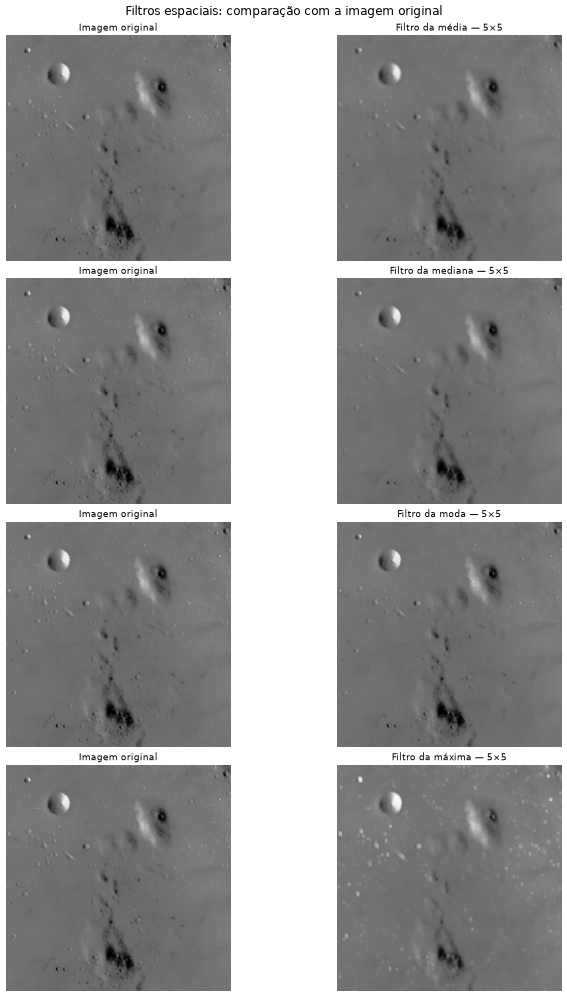

In [4]:
tamanho_janela = 5
resultados = [
    ("Média", filtro_media(imagem_original, tamanho_janela)),
    ("Mediana", filtro_mediana(imagem_original, tamanho_janela)),
    ("Moda", filtro_moda(imagem_original, tamanho_janela)),
    ("Máxima", filtro_maxima(imagem_original, tamanho_janela)),
]

fig, eixos = plt.subplots(4, 2, figsize=(12, 18), constrained_layout=True)
for linha, (nome, imagem_filtrada) in enumerate(resultados):
    eixos[linha, 0].imshow(imagem_original, cmap="gray", vmin=0, vmax=255)
    eixos[linha, 0].set_title("Imagem original")
    eixos[linha, 1].imshow(imagem_filtrada, cmap="gray", vmin=0, vmax=255)
    eixos[linha, 1].set_title(f"Filtro da {nome.lower()} — {tamanho_janela}×{tamanho_janela}")
    for eixo in eixos[linha]:
        eixo.axis("off")

fig.suptitle("Filtros espaciais: comparação com a imagem original", fontsize=16)
plt.show()


## Observações

- **Média:** suaviza a imagem ao calcular a média da vizinhança.
- **Mediana:** usa o valor central após ordenar a janela; costuma preservar melhor as bordas que a média.
- **Moda:** escolhe o valor mais frequente na janela, com desempate determinístico.
- **Máxima:** seleciona o maior valor local e expande regiões claras.

A função `convolucao_manual` é usada pelo filtro da média. Os outros três são não lineares e, por isso, são calculados diretamente sobre cada janela.
